In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras.models import load_model
import torch
import torch.nn as nn
import joblib
import json
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import architec as acht
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [20]:
MaxNum = 20
emer_list = ["sta_entropy", "diversity"]
ecol_list = ["density", "negmean", "posinall"]
extra_list = ["ascend", "descend"]

emer_property = emer_list[1]
ecol_property = ecol_list[2]

all_metrics = []

for rep in range(3):

    for extra_direction in extra_list:

        split_df = pd.read_csv(f"split_{ecol_property}_{extra_direction}/split_{rep+1}.csv")
        folder_path = "../../Databases/Ver2.0/ver2.0_upto20"
        load_dir = Path(f"../../saved_models/{emer_property}_extrapolation/{ecol_property}_{extra_direction}_r{rep+1}")
        model = func.load_saved_model_MD(load_dir, device)
        evaluator = func.TrteEvaluator(model)

        for rich in range(3, 21):
            narray_te, _ = prep.load_split_dataset3(
                split_df,
                folder_path,
                richness_list=[rich],
                #richness_list=list(range(3,21)),
                subset="te",
                sur_frac=False,
                MaxNum=MaxNum,
                #sample_size=17000,
            )

            y_te, y_pred = evaluator.predict_array_MD(narray_te, device, sample_size=None)

            metrics = eva.eval_regression(y_te, y_pred)
            metrics["rep"] = rep + 1
            metrics["test_richness"] = rich
            metrics["train_tag"] = extra_direction
            all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
df_metrics.to_pickle(f"{emer_property}_{ecol_property}.pkl")


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (18283, 465)
te shape = (18142, 465)
te shape = (18082, 465)
te shape = (18022, 465)
te shape = (17868, 465)
te shape = (17718, 465)
te shape = (17618, 465)
te shape = (17583, 465)
te shape = (17465, 465)
te shape = (17476, 465)
te shape = (17315, 465)
te shape = (17362, 465)
te shape = (17186, 465)
te shape = (17068, 465)
te shape = (17029, 465)
te shape = (16951, 465)
te shape = (16926, 465)
te shape = (16851, 465)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (18283, 465)
te shape = (18142, 465)
te shape = (18082, 465)
te shape = (18022, 465)
te shape = (17868, 465)
te shape = (17718, 465)
te shape = (17618, 465)
te shape = (17583, 465)
te shape = (17465, 465)
te shape = (17476, 465)
te shape = (17315, 465)
te shape = (17362, 465)
te shape = (17186, 465)
te shape = (17068, 465)
te shape = (17029, 465)
te shape = (16951, 465)
te shape = (16926, 465)
te shape = (16851, 465)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


...

te shape = (18263, 465)
te shape = (18171, 465)
te shape = (18072, 465)
te shape = (17874, 465)
te shape = (17837, 465)
te shape = (17728, 465)
te shape = (17630, 465)
te shape = (17589, 465)
te shape = (17546, 465)
te shape = (17494, 465)
te shape = (17361, 465)
te shape = (17266, 465)
te shape = (17202, 465)
te shape = (17059, 465)
te shape = (17007, 465)
te shape = (17006, 465)
te shape = (16992, 465)
te shape = (16848, 465)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (18246, 465)
te shape = (18098, 465)
te shape = (18095, 465)
te shape = (17946, 465)
te shape = (17861, 465)
te shape = (17759, 465)
te shape = (17653, 465)
te shape = (17601, 465)
te shape = (17581, 465)
te shape = (17393, 465)
te shape = (17353, 465)
te shape = (17212, 465)
te shape = (17144, 465)
te shape = (17078, 465)
te shape = (17029, 465)
te shape = (16978, 465)
te shape = (17021, 465)
te shape = (16897, 465)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (18246, 465)
te shape = (18098, 465)
te shape = (18095, 465)
te shape = (17946, 465)
te shape = (17861, 465)
te shape = (17759, 465)
te shape = (17653, 465)
te shape = (17601, 465)
te shape = (17581, 465)
te shape = (17393, 465)
te shape = (17353, 465)
te shape = (17212, 465)
te shape = (17144, 465)
te shape = (17078, 465)
te shape = (17029, 465)
te shape = (16978, 465)
te shape = (17021, 465)
te shape = (16897, 465)


In [21]:
#df_metrics = pd.read_pickle("surround.pkl")

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis labels (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

colors = ["#40a6bd", "#cf8c51", "#F8CE45", '#626c83']

plot_df = (df_metrics.groupby(["train_tag", "test_richness"])["R2"]
               .agg(mean="mean", min="min", max="max").reset_index())


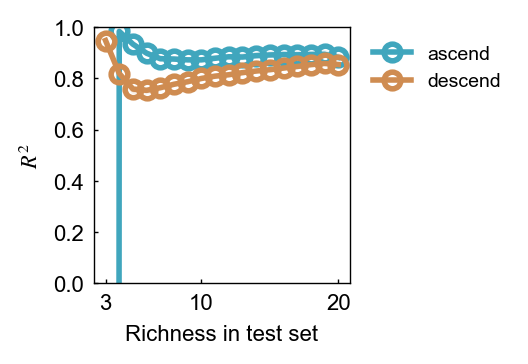

In [22]:
plt.figure(figsize=(1.6, 1.6), dpi=200)

for i, (train_tag, grp) in enumerate(plot_df.groupby("train_tag")):

    grp = grp.sort_values("test_richness")

    color = colors[i % len(colors)]

    plt.plot(
        grp["test_richness"],
        grp["mean"],
        color=color,
        marker='o',
        markersize=6,
        markerfacecolor='none',
        markeredgewidth=2,
        linewidth=2,
        label=train_tag
    )

    poly = plt.fill_between(
        grp["test_richness"],
        grp["min"],
        grp["max"],
        color=color,
        alpha=0.1
    )

    poly.set_rasterized(True) # Rasterize transparent areas

plt.xlabel("Richness in test set")
plt.ylabel(r"$R^2$")
plt.xticks([3,10,20])
plt.ylim(0,1)
plt.tick_params(direction='in')
plt.grid(False)
plt.legend(
    #title="Training richness",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.subplots_adjust(left=0.18, right=0.98, bottom=0.18, top=0.98)

plt.savefig(
    f"{emer_property}_{ecol_property}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight', # Auto-trim extra whitespace around figure
    transparent=True,
)

plt.show()
